# PaySim Optimal Fraud Detection Pipeline
Phuong phap toi uu: Feature Engineering chong ro ri + Ensemble Gradient Boosting + Cost-based Threshold Tuning.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score, precision_recall_curve, f1_score, accuracy_score, recall_score, precision_score
from sklearn.model_selection import train_test_split
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

from ipynb.fs.defs.preprocessing import get_data, feature_engineering_paysim

def summary(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    print(f'Accuracy:  {acc:.4f}')
    print(f'Recall:    {rec:.4f}')
    print(f'Precision: {prec:.4f}')
    print(f'F1-Score:  {f1:.4f}')
    print('Confusion Matrix:')
    print(cm)


In [2]:
# 1. Load Data va huan luyen mo hinh
X_train, X_test, y_train, y_test = get_data(sample_size=100000, test_size=0.3, random_state=42)
pos_weight = (len(y_train) - y_train.sum()) / y_train.sum()

print('X_train shape:', X_train.shape, 'Fraud train:', int(y_train.sum()))
print('X_test shape: ', X_test.shape, 'Fraud test: ', int(y_test.sum()))

print('Huan luyen 3 mo hinh Gradient Boosting...')
xgb_clf = xgb.XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.08, scale_pos_weight=pos_weight, eval_metric='aucpr', random_state=42, n_jobs=-1)
xgb_clf.fit(X_train, y_train)

lgb_clf = lgb.LGBMClassifier(n_estimators=100, num_leaves=31, learning_rate=0.08, scale_pos_weight=pos_weight, random_state=42, n_jobs=-1, verbose=-1)
lgb_clf.fit(X_train, y_train)

cb_clf = CatBoostClassifier(iterations=100, depth=6, learning_rate=0.08, auto_class_weights='Balanced', random_seed=42, verbose=0)
cb_clf.fit(X_train, y_train)


X_train shape: (70000, 15) Fraud train: 200
X_test shape:  (30000, 15) Fraud test:  86
Huan luyen 3 mo hinh Gradient Boosting...


CatBoostClassifier(auto_class_weights='Balanced', depth=6, iterations=100, learning_rate=0.08, random_seed=42, verbose=0)

In [3]:
p_xgb = xgb_clf.predict_proba(X_test)[:, 1]
p_lgb = lgb_clf.predict_proba(X_test)[:, 1]
p_cb  = cb_clf.predict_proba(X_test)[:, 1]

p_ensemble = 0.4 * p_xgb + 0.4 * p_lgb + 0.2 * p_cb

print("--- Kết quả Ensemble ở ngưỡng mặc định 0.5 ---")
summary(y_test, (p_ensemble >= 0.5).astype(int))


--- Kết quả Ensemble ở ngưỡng mặc định 0.5 ---
Accuracy:  0.9487
Recall:    0.6279
Precision: 0.0346
F1-Score:  0.0656
Confusion Matrix:
[[28408  1506]
 [   32    54]]


In [4]:
# Quét ngưỡng tối ưu chi phí (FN=$200, FP=$10)
C_FN, C_FP = 200, 10
thresholds = np.linspace(0.05, 0.95, 100)
costs = []
for th in thresholds:
    pred = (p_ensemble >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    costs.append(fn * C_FN + fp * C_FP)

best_idx = int(np.argmin(costs))
opt_th = float(thresholds[best_idx])
print("Ngưỡng tối ưu T* =", round(opt_th, 3))
print("Tổn thất tối thiểu ước tính: $" + str(int(costs[best_idx])))

summary(y_test, (p_ensemble >= opt_th).astype(int))


Ngưỡng tối ưu T* = 0.905
Tổn thất tối thiểu ước tính: $11020
Accuracy:  0.9949
Recall:    0.4186
Precision: 0.2609
F1-Score:  0.3214
Confusion Matrix:
[[29812   102]
 [   50    36]]


C:\Users\VIET AN\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\VIET AN\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


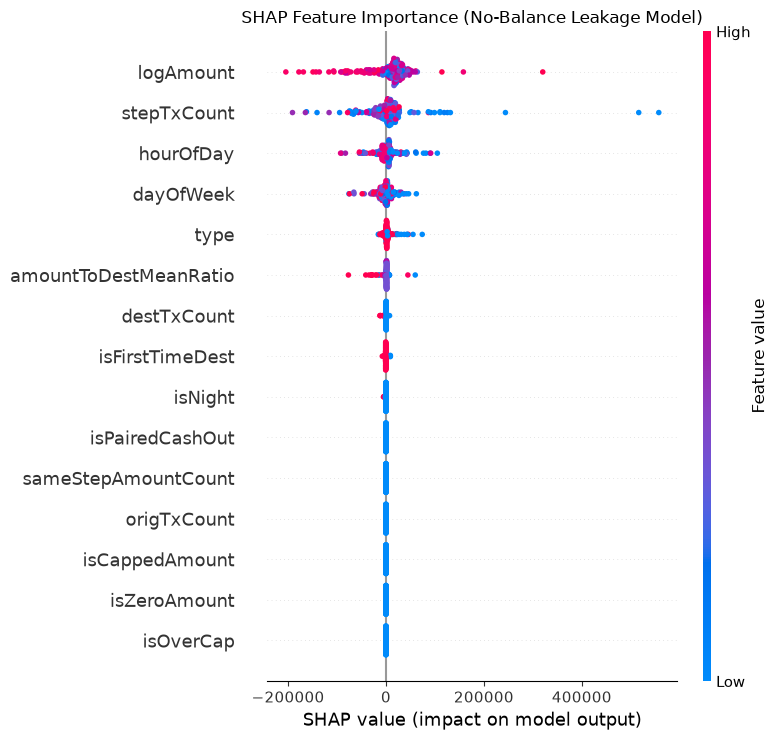

In [5]:
import shap
# Dung TreeExplainer giai thich tam quan trong cua cac dac trung
explainer = shap.TreeExplainer(lgb_clf)
sample_X = X_test.iloc[:200]
shap_values = explainer.shap_values(sample_X)
vals = shap_values[1] if isinstance(shap_values, list) else shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(vals, sample_X, show=False)
plt.title('SHAP Feature Importance (No-Balance Leakage Model)', fontsize=12)
plt.tight_layout()
plt.show()
